# Tukey API

- This notebook tours the Tukey API: a Gym-style environment that hides a
  random causal graph, statistical tools an agent can call on the training
  data, a verifiable score, and the baselines a learned policy must beat
- The pedagogical arc:
  - Part 1: check the environment and the pinned scientific stack
  - Part 2: sample a hidden graph and score candidate graphs against it
  - Part 3: call the statistical tools, run the scripted agent and the
    baselines
- This version covers Milestones 1-2; the learned policy (Milestone 3) and
  the Milestone 4 additions arrive with the next PRs

In [1]:
%load_ext autoreload
%autoreload 2

import logging

import numpy as np

In [2]:
import helpers.hintrospection as hintros
import helpers.hnotebook as hnotebook
import tukey_utils as utils
import tukey_env as tenv
import tukey_scripted as tscrip
import tukey_tools as ttools

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmp97uw3dgp.json --HistoryManager.hist_file=:memory:


## Library Overview

- **What problem it solves**: learning which statistical test to run next on
  an unknown dataset, rewarded by how well the emitted graph matches the
  hidden graph that generated the data
- **Key abstraction**: an episode = sample a hidden graph and data, call
  tools on the training rows, emit a graph, receive a verifiable score
- **Mental model**:

| Object | Description | Comments |
|--------|-------------|----------|
| `GraphConfig` | Generator settings | Size, family, noise, topology, scaling |
| `sample_instance(cfg, seed)` | Hidden graph, data, split | Reproducible |
| `TukeyEnv.reset(seed=...)` | Starts an episode | Returns `Evidence` |
| `TukeyEnv.step(action)` | Runs one tool call or STOP | Reward = call cost |
| `TukeyEnv.submit_graph(edges)` | Scores an emitted graph | Ends the episode |
| `score_graph(B, truth)` | Verifiable score | Structure + prediction |

- **Key classes**:
  - `TukeyEnv`: the environment
  - `Evidence`: everything an agent sees (correlations and its own calls)
  - `ScriptedExpert`: the prototype's rule as an agent

# Part 1: Environment check

## Cell 1.1: Pinned scientific stack

**Goal**
- Confirm the container runs the pinned versions the results were produced
  with

In [3]:
# Report the version of every package the project depends on.
versions = utils.cell1_1_get_package_versions()
display(versions)
# Outcome: one row per core package, each at the version pinned in
# `requirements.txt`.

,package,version
0,numpy,2.5.4
1,pandas,3.0.6
2,scipy,1.18.1
3,scikit-learn,1.9.1
4,networkx,3.7
5,causal-learn,0.1.4.8
6,lingam,1.12.2
7,CausalDisco,0.2.4
8,pgmpy,1.1.2
9,torch,2.14.0+cpu


**Implementation** `cell1_1_get_package_versions()`
- Reads each version from the installed distribution metadata

In [4]:
hintros.print_obj_info(utils.cell1_1_get_package_versions)

- `cell1_1_get_package_versions(*, packages: Tuple[str, ...] = ('numpy', 'pandas', 'scipy', 'scikit-learn', 'networkx', 'causal-learn', 'lingam', 'CausalDisco', 'pgmpy', 'torch')) -> pandas.DataFrame`  
  Report the installed version of each package the project depends on.

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA_2/class_project/msml610/Fall2026/projects/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA/tukey_utils.py#L68


# Part 2: A hidden graph and its score

## Cell 2.1: Configure and sample an instance

**Goal**
- Sample one hidden causal world and see what is stored about it

In [5]:
# Six variables, seven edges, Gaussian noise with unequal variances.
cfg = tenv.GraphConfig(n_nodes=6, n_edges=7, family="linear_gauss")
inst = tenv.sample_instance(cfg, seed=3)
display(utils.cell2_1_describe_instance(inst))
# Outcome: the target class is the CPDAG: with Gaussian noise and unequal
# variances the data identify only the Markov equivalence class.

,n_nodes,n_edges,family,noise,mechanism,target_class,target_reason,n_train,n_test
0,6,7,linear_gauss,gaussian,linear,cpdag,linear Gaussian: equivalence class only,2009,991


In [6]:
# The training rows, standardized with their own statistics.
display(inst.d_train.head())

,x0,x1,x2,x3,x4,x5
0,0.703490,0.377676,0.735081,0.480425,-0.956809,1.371129
1,-1.112183,-1.585478,-0.765519,-0.574673,1.605750,-1.033352
2,0.090271,-0.450947,0.431006,-0.858743,-0.063308,-0.691886
3,0.650571,-0.326765,0.279714,0.514835,-0.614987,1.336000
4,0.052264,-0.718264,-0.259396,0.232935,-0.334862,0.105806


In [7]:
hintros.print_obj_info(tenv.GraphConfig)

**GraphConfig**

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA_2/class_project/msml610/Fall2026/projects/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA/tukey_env.py#L110


## Cell 2.2: Plot the hidden graph

**Goal**
- See the answer an agent must recover (agents never see it)

**Description**
- `Hidden graph G*`: one node per column of the data; an arrow x_i -> x_j
  means x_i is a direct cause of x_j

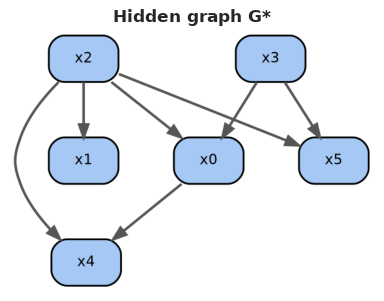

In [8]:
# Draw G*.
utils.cell2_2_plot_graph(inst.truth.B, "Hidden graph G*")

**Implementation** `cell2_2_plot_graph()`
- Builds a `networkx` graph from the adjacency and draws it with the course's
  `plot_causal_dag()` style

In [9]:
hintros.print_obj_info(utils.cell2_2_plot_graph)

- `cell2_2_plot_graph(B: numpy.ndarray, title: str, *, figsize: Tuple[int, int] = (4, 4)) -> None`  
  Plot a DAG with the course's causal-DAG style.

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA_2/class_project/msml610/Fall2026/projects/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA/tukey_utils.py#L118


## Cell 2.3: Score candidate graphs

**Goal**
- Read the score on graphs whose quality is known in advance

**Description**
- `score`: `-0.5 * shd_target / |E*| - 0.5 * (1 - pred_frac)`; G* scores 0,
  the empty graph -1
- `shd_target`: structural distance to the identifiable target (here the
  CPDAG); `shd_dag`, `shd_cpdag`: the same against the DAG and its class
- `pred_frac`: held-out likelihood gain over the empty graph, relative to G*

In [10]:
# Score G*, the empty graph and four edits of G*.
display(utils.cell2_3_score_candidates(inst))
# Outcome: G* scores 0 and the empty graph -1; reversing a covered edge stays in
# the equivalence class, so it scores exactly like G* against the CPDAG target
# while `shd_dag` still counts it; reversing an uncovered edge changes the class
# and costs structure and prediction; extra edges (complete order) leave
# `pred_frac` near 1, so only the structural term penalizes them.

,candidate,score,shd_target,shd_dag,shd_cpdag,pred_frac
0,G* (the answer),0.000,0,0,0,1.000
1,empty graph,-1.000,7,7,7,0.000
2,covered edge reversed,0.000,0,1,0,1.000
3,uncovered edge reversed,-0.198,2,1,2,0.890
4,all edges reversed,-0.681,7,7,7,0.637
5,complete order,-1.000,14,11,14,0.999


**Implementation** `cell2_3_score_candidates()`
- Edits G* (a covered and an uncovered reversal, all reversals, the complete
  graph along one order) and calls `score_graph()` on each

In [11]:
hintros.print_obj_info(utils.cell2_3_score_candidates)

- `cell2_3_score_candidates(inst: tukey_env.Instance) -> pandas.DataFrame`  
  Score G*, the empty graph and a few edits of G* against the instance.

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA_2/class_project/msml610/Fall2026/projects/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA/tukey_utils.py#L164


## Cell 2.4: Run an episode

**Goal**
- Walk through `reset()`, `step()` and `submit_graph()`

In [12]:
# Start an episode with a budget of 5 tool calls.
env = tenv.TukeyEnv(cfg, budget=5)
evidence, info = env.reset(seed=3)
display(info)
# Outcome: `info` holds only sizes and costs, never the hidden graph.

{'n_nodes': 6,
 'n_train': 2009,
 'budget': 5,
 'tool_costs': {'ci_test': 0.001,
  'regress': 0.001,
  'lingam_dir': 0.001,
  'nongauss': 0.001,
  'variance': 0.001,
  'mutual_info': 0.001,
  'stop': 0.0}}

In [13]:
# Run one conditional-independence test: x0 independent of x1 given x2?
action = ttools.ci_test_action(0, 1, (2,))
evidence, reward, terminated, truncated, _ = env.step(action)
print("result:", evidence.results[action])
print("reward:", reward, "terminated:", terminated, "truncated:", truncated)
# Outcome: the partial correlation, its Fisher z and p-value; the reward is
# the call's training cost.

result: {'pcorr': -0.002780971987486798, 'z': -0.12452453318597698, 'p': 0.9008999768793898}
reward: -0.001 terminated: False truncated: False


In [14]:
# Emit G* itself as an edge list and score it.
edges = [(int(i), int(j)) for i, j in np.argwhere(inst.truth.B == 1)]
scores = env.submit_graph(edges)
print("score:", scores["score"], "shd_target:", scores["shd_target"])
print("calls used:", scores["calls_used"])
# Outcome: the hidden graph scores 0 with one call used.

score: 0.0 shd_target: 0
calls used: 1


In [15]:
hintros.print_obj_info(tenv.TukeyEnv)

**TukeyEnv**
- `legal_actions(self) -> List[tukey_tools.Action]`: List the tool calls still allowed, plus STOP.
- `reset(self, *, seed: int) -> Tuple[tukey_tools.Evidence, Dict[str, Any]]`: Sample a new instance and start an episode.
- `reward_oracle(self, *, lam: float = 0.5) -> Callable[[numpy.ndarray], float]`: Return a function that scores any DAG on the current instance.
- `step(self, action: tukey_tools.Action) -> Tuple[tukey_tools.Evidence, float, bool, bool, Dict[str, Any]]`: Run one tool call, or STOP.
- `submit_graph(self, edges: List[Tuple[int, int]]) -> Dict[str, Any]`: Score a discovered graph (the prototype's `graph.json` contract).

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA_2/class_project/msml610/Fall2026/projects/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA/tukey_env.py#L1344


# Part 3: Tools, the scripted agent and the baselines

## Cell 3.1: Call each tool once

**Goal**
- See what each statistical tool returns

In [16]:
# A fresh episode, then one call of each tool on x0, x1 (given x2).
evidence, _ = env.reset(seed=3)
display(utils.cell3_1_call_each_tool(evidence, 0, 1, 2))
# Outcome: correlations and regressions are scale-free; only `variance` sees
# the raw scale (0 here, since the data are standardized).

,tool,args,result
0,ci_test,"(0, 1, 2)","pcorr=-0.00278, z=-0.125, p=0.901"
1,regress,"(1, 0)","r2=0.474, coef_0=0.689, t_0=42.6, p_0=1.02e-28..."
2,lingam_dir,"(0, 1)",stat=-0.000212
3,nongauss,"(0,)","skew=-0.0272, kurt=0.0254, jb_p=0.86"
4,variance,"(0,)",log_var=-2.22e-16


**Implementation** `cell3_1_call_each_tool()`
- Records each call in the evidence, which caches results per dataset

In [17]:
hintros.print_obj_info(ttools.ToolCache)

**ToolCache**
- `fisher_z(self, r: float, n_cond: int) -> Tuple[float, float]`: Compute the Fisher z statistic and two-sided p-value of a correlation.
- `run(self, action: tukey_tools.Action) -> Dict[str, float]`: Run a tool, from the cache when possible.

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA_2/class_project/msml610/Fall2026/projects/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA/tukey_tools.py#L170


## Cell 3.2: Run the prototype's rule as an agent

**Goal**
- Play the prototype's scripted rule through the tool API and check it emits
  the prototype's graph

In [18]:
# The prototype's own setting (exponential noise, raw scale), unlimited budget.
proto_env = tenv.TukeyEnv(tenv.PROTO_CONFIG, budget=1000)
scores, history = tscrip.run_episode(proto_env, tscrip.ScriptedExpert(), seed=0)
print("calls:", len(history), "shd:", scores["shd"], "f1:", scores["f1"])
reference = tscrip.proto_faithful_edges(proto_env.d_train.to_numpy())
print("prototype's edges:", reference)
# Outcome: SHD 3 and F1 0.667, the prototype's numbers on seed 0.

calls: 55 shd: 3 f1: 0.667


prototype's edges: [(3, 0), (0, 4), (2, 1), (3, 2), (3, 5), (5, 4)]


In [19]:
hintros.print_obj_info(tscrip.ScriptedExpert)

**ScriptedExpert**
- `emit_graph(self, evidence: tukey_tools.Evidence) -> List[Tuple[int, int]]`: Emit a DAG: the rule's edges with cycles removed by `project_to_dag()`.
- `emit_raw_edges(self, evidence: tukey_tools.Evidence) -> List[Tuple[int, int]]`: Emit the rule's edges from the evidence, possibly with cycles.
- `next_action(self, evidence: tukey_tools.Evidence) -> tukey_tools.Action`: Return the rule's next tool call, or STOP when done or out of budget.

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA_2/class_project/msml610/Fall2026/projects/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA/tukey_scripted.py#L142


## Cell 3.3: Compare the baselines on one instance

**Goal**
- Run the classical and sort-and-regress baselines on the instance of Part 2

In [20]:
# Every baseline sees only the training rows.
display(utils.cell3_3_compare_baselines(inst))
# Outcome: on Gaussian data the CPDAG methods (PC, GES) can match the target;
# DirectLiNGAM assumes non-Gaussian noise and orients at random here; sorting by
# the number of relatives can recover the class (the sortability of Milestone 1);
# the empty graph scores -1.

,baseline,output,score,shd_target,seconds
0,pc,pdag,0.000,0,0.007
1,ges,pdag,0.000,0,0.012
2,direct_lingam,dag,-0.643,9,0.027
3,var_sort_regress,dag,-0.786,11,0.007
4,r2_sort_regress,dag,-0.857,12,0.006
5,rel_sort_regress,dag,0.000,0,0.006
6,random_sort_regress,dag,-1.000,14,0.007
7,empty,dag,-1.000,7,0.000


**Implementation** `cell3_3_compare_baselines()`
- Calls `run_baseline()` and `score_output()` for each name in `BASELINES`

In [21]:
hintros.print_obj_info(utils.cell3_3_compare_baselines)

- `cell3_3_compare_baselines(inst: tukey_env.Instance) -> pandas.DataFrame`  
  Run every baseline on one instance and score it.

https://github.com/gpsaggese/gpsaggese.github.io/blob/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA_2/class_project/msml610/Fall2026/projects/UmdTask628_MSML610_Fall2026_Tukey_RL_agent_for_automated_EDA/tukey_utils.py#L238


## Summary: The Mental Model

- An instance hides a graph; an agent sees only the training rows through
  `Evidence`, and the score compares its graph with what the data identify
- The score is 0 for the hidden graph and -1 for the empty graph, and graphs
  in the same equivalence class tie when only the class is identifiable
- Tools are pure functions of the training rows; the scripted agent and the
  baselines use the same interface that the learned policy of Milestone 3
  will use